# Bank Marketing — Final Evaluation

## 1. Introduction

이 노트북에서는 모델 실험에서 선택한 Logistic Regression을 Train+Validation에 학습하고
개발에서 제외한 Test에서 최종 순위 성능을 평가한다.

- Notebook 04에서 확정한 feature 정책, sentinel-aware 전처리와 모델 설정을 유지한다.
- 전처리와 모델을 새로 구성해 Train+Validation에서만 fit한다.
- Test에서 AP, ROC-AUC와 Top-5/10/20% 지표를 평가한다.
- Test 결과로 모델이나 평가 규칙을 다시 선택하지 않는다.

## 2. Data & Pipeline Setup

### 2.1 Load Data & Splits

원본 행 순서를 유지해 앞의 37,069행을 Train+Validation, 나머지 4,119행을 Test로 준비한다.
기존 경계를 다시 계산하거나 셔플하지 않는다. `y`와 `duration`을 제외한 19개 입력을 사용하고,
Target은 `no = 0`, `yes = 1`로 인코딩한다.

실행 환경과 파일 출처를 함께 기록한다. 아래 hash 출력은 Test 접근 전 Notebook 04
확정본의 식별값이며, 이후 설명을 편집한 현재 파일의 hash를 뜻하지 않는다.

In [1]:
import hashlib
import platform
from importlib.metadata import version
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    PrecisionRecallDisplay,
    average_precision_score,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

pd.Series(
    {
        "python": platform.python_version(),
        "numpy": version("numpy"),
        "pandas": version("pandas"),
        "scikit-learn": version("scikit-learn"),
        "scipy": version("scipy"),
    },
    name="version",
)

python          3.12.15
numpy             2.5.3
pandas            3.0.6
scikit-learn      1.9.1
scipy            1.18.1
Name: version, dtype: str

In [4]:
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
RAW_DATA_PATH = (
    PROJECT_ROOT / "data" / "raw" / "bank-additional" / "bank-additional-full.csv"
)

train_valid_end = 37069
df = pd.read_csv(RAW_DATA_PATH, sep=";")
train_valid_df = df.iloc[:train_valid_end].copy()
test_df = df.iloc[train_valid_end:].copy()

modeling_features = [column for column in df.columns if column not in ["y", "duration"]]
target_mapping = {"no": 0, "yes": 1}
X_train_valid = train_valid_df[modeling_features].copy()
y_train_valid = train_valid_df["y"].map(target_mapping)
X_test = test_df[modeling_features].copy()
y_test = test_df["y"].map(target_mapping)

pd.DataFrame(
    {
        "rows": [len(X_train_valid), len(X_test)],
        "features": [X_train_valid.shape[1], X_test.shape[1]],
        "positive_records": [int(y_train_valid.sum()), int(y_test.sum())],
        "positive_rate": [y_train_valid.mean(), y_test.mean()],
    },
    index=["Train+Validation", "Test"],
)

,rows,features,positive_records,positive_rate
Train+Validation,37069,19,2748,0.074132
Test,4119,19,1892,0.459335


In [5]:
with RAW_DATA_PATH.open("rb") as raw_file:
    raw_sha256 = hashlib.file_digest(raw_file, "sha256").hexdigest()
print("Source: UCI Bank Marketing / bank-additional-full.csv")
print("SHA-256:", raw_sha256)
print(
    "Frozen development notebook SHA-256:",
    "187186e12721f75e7f8d5c1dabdd8207b49d0e010ff3da35af489e75d6a4c953",
)

Source: UCI Bank Marketing / bank-additional-full.csv
SHA-256: 74adfc578bf77a7ff4bb1ba4a9f8709d9e3c6907342959c2c8416847e0afb4d8
Frozen development notebook SHA-256: 187186e12721f75e7f8d5c1dabdd8207b49d0e010ff3da35af489e75d6a4c953


### 2.2 Sentinel-Aware Preprocessing

Notebook 02·03과 같은 feature 그룹과 변환을 사용한다. 일반 수치형 8개와
`pdays`의 이전 연락 여부·경과 일수 2개를 scaling하고 범주형 10개는 one-hot encoding한다.
`unknown`은 범주로 유지하고, `999`는 경과 일수로 사용하지 않는다.

[모델 실험](04-model-experiments.ipynb)에서 Test 접근 전에 선택한 모델은
`LogisticRegression(C=1.0, solver="lbfgs", max_iter=1000, tol=0.0001)`이다.
나머지 파라미터는 확정한 scikit-learn 1.9.1 기본값을 유지한다.

In [2]:
numeric_features = [
    "age",
    "campaign",
    "previous",
    "emp.var.rate",
    "cons.price.idx",
    "cons.conf.idx",
    "euribor3m",
    "nr.employed",
]

categorical_features = [
    "job",
    "marital",
    "education",
    "default",
    "housing",
    "loan",
    "contact",
    "month",
    "day_of_week",
    "poutcome",
]


def split_pdays(values):
    pdays = np.asarray(values).reshape(-1)
    previously_contacted = (pdays != 999).astype(float)
    elapsed_days = np.where(pdays == 999, 0.0, pdays.astype(float))
    return np.column_stack([previously_contacted, elapsed_days])


def pdays_feature_names(transformer, input_features):
    return np.asarray(
        ["pdays_previously_contacted", "pdays_elapsed"],
        dtype=object,
    )

In [3]:
pdays_transformer = Pipeline(
    steps=[
        (
            "derive",
            FunctionTransformer(
                split_pdays,
                validate=False,
                feature_names_out=pdays_feature_names,
            ),
        ),
        ("scale", StandardScaler()),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features,
        ),
        ("pdays", pdays_transformer, ["pdays"]),
    ],
    remainder="drop",
)

final_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(C=1.0, solver="lbfgs", max_iter=1000, tol=0.0001)),
    ]
)

## 3. Final Training

새 전체 Pipeline을 Train+Validation에서 fit한다. Scaler 통계, encoder 범주와
모델 계수 학습에 Test를 사용하지 않는다. 학습 후 반복 횟수와 변환 feature 수를 확인한다.

In [6]:
fit_start = perf_counter()
final_pipeline.fit(X_train_valid, y_train_valid)
fit_seconds = perf_counter() - fit_start

fitted_model = final_pipeline.named_steps["model"]
pd.Series(
    {
        "training_rows": len(X_train_valid),
        "fit_seconds": fit_seconds,
        "optimization_iterations": int(fitted_model.n_iter_[0]),
        "transformed_features": int(fitted_model.n_features_in_),
    },
    name="final_training",
)

training_rows              37069.000000
fit_seconds                    1.135969
optimization_iterations       46.000000
transformed_features          62.000000
Name: final_training, dtype: float64

## 4. Final Evaluation

Test 양성 클래스 점수를 한 번 계산하고 같은 점수로 모든 지표와 그래프를 만든다.
AP를 주요 순위 지표로, ROC-AUC를 보조 판별 지표로 사용하며 Test 양성 비율을 함께 보고한다.

In [7]:
score_start = perf_counter()
y_test_score = final_pipeline.predict_proba(X_test)[:, 1]
score_seconds = perf_counter() - score_start

test_prevalence = y_test.mean()
test_ap = average_precision_score(y_test, y_test_score)
test_roc_auc = roc_auc_score(y_test, y_test_score)

pd.Series(
    {
        "test_rows": len(y_test),
        "positive_records": int(y_test.sum()),
        "test_prevalence": test_prevalence,
        "average_precision": test_ap,
        "roc_auc": test_roc_auc,
        "score_seconds": score_seconds,
    },
    name="Final Logistic Regression",
).to_frame().round(6)

,Final Logistic Regression
test_rows,4119.000000
positive_records,1892.000000
test_prevalence,0.459335
average_precision,0.549042
roc_auc,0.620009
score_seconds,0.023811


### 4.1 Top-K Ranking Metrics

상위 5%, 10%, 20%에서 `K = ceil(n*p)`를 사용하고 반올림하지 않은 점수를
내림차순 stable sort로 정렬한다. 동점은 원본 순서로 처리하며 Lift는 Test 양성 비율을 기준으로 한다.

In [8]:
ranked_indices = np.argsort(-y_test_score, kind="stable")
ranked_y = y_test.to_numpy()[ranked_indices]
cumulative_positives = np.cumsum(ranked_y)
total_positives = int(y_test.sum())

ranking_rows = []
for fraction in [0.05, 0.10, 0.20]:
    k = int(np.ceil(len(y_test) * fraction))
    captured = int(cumulative_positives[k - 1])
    precision = captured / k

    ranking_rows.append(
        {
            "top_fraction": fraction,
            "k": k,
            "captured_subscribers": captured,
            "precision_at_k": precision,
            "recall_at_k": captured / total_positives,
            "lift_at_k": precision / test_prevalence,
        }
    )

test_ranking_results = pd.DataFrame(ranking_rows)
test_ranking_results.round(6)

,top_fraction,k,captured_subscribers,precision_at_k,recall_at_k,lift_at_k
0,0.05,206,128,0.621359,0.067653,1.352737
1,0.10,412,211,0.512136,0.111522,1.114951
2,0.20,824,432,0.524272,0.228330,1.141372


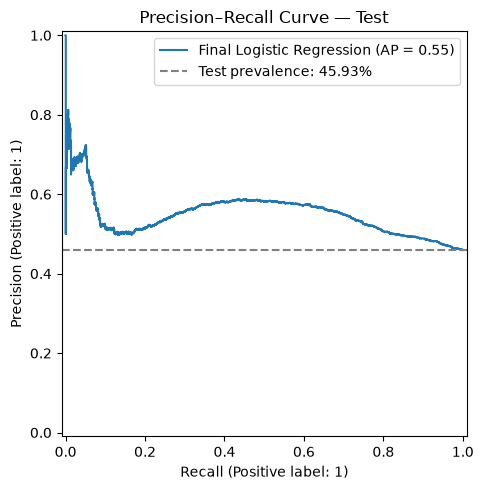

In [9]:
fig, ax = plt.subplots(figsize=(8, 5))
PrecisionRecallDisplay.from_predictions(
    y_test, y_test_score, name="Final Logistic Regression", ax=ax
)
ax.axhline(
    test_prevalence,
    color="gray",
    linestyle="--",
    label=f"Test prevalence: {test_prevalence:.2%}",
)
ax.set_title("Precision–Recall Curve — Test")
ax.legend()
plt.tight_layout()
plt.show()

### 4.2 Results & Interpretation

Test AP는 `0.549042`, ROC-AUC는 `0.620009`이다. 가입 레코드는 4,119개 중 1,892개이며
양성 비율은 45.93%이다. AP는 이 양성 비율을 웃돌지만 클래스 구분 능력은 제한적이다.

상위 5%의 206개 중 가입 레코드 128개를 포함한다. Precision은 62.14%, Recall은 6.77%,
Lift는 1.35이다. 상위 10%에서는 412개 중 211개를 포함해 Precision 51.21%, Recall 11.15%,
Lift 1.11을 얻는다. 상위 20%에서는 824개 중 432개를 포함하며 Precision 52.43%,
Recall 22.83%, Lift 1.14이다.

용량이 늘면 Recall은 증가하지만 관측된 누적 Precision은 반드시 감소하지 않는다.
상위 20%의 Precision이 상위 10%보다 조금 높은 것은 그 구간의 가입 레코드 분포를 반영한다.
어느 용량도 비용과 가입 가치가 없는 상태에서 운영 권고안으로 해석할 수 없다.

Validation AP `0.288234`보다 Test AP가 높지만 양성 비율이 13.86%에서 45.93%로 바뀌었고
학습 범위도 달라졌다. 모델 개선이나 안정성 향상의 증거가 아니다.
Test Lift@10% `1.114951`은 후기 기간에서 상위 순위 집중도가 제한적임을 보여준다.

## 5. Final Evaluation Summary

| 구성 요소 | 설정 |
|---|---|
| 모델 | Sentinel-aware Logistic Regression; `C=1.0`, `solver="lbfgs"`, `max_iter=1000`, `tol=0.0001` |
| 전처리 | 일반 수치형 8개와 `pdays` 파생 2개 scaling, 범주형 10개 one-hot |
| 학습 범위 | Train+Validation 37,069행 |
| 평가 범위 | Test 4,119행 |
| 변환 후 feature | 62개 |

| Test 지표 | 결과 |
|---|---:|
| Average Precision | 0.549042 |
| ROC-AUC | 0.620009 |
| Precision@10% | 0.512136 |
| Recall@10% | 0.111522 |
| Lift@10% | 1.114951 |

확정한 구성 하나를 평가했으며 결과로 tuning, 모델 재선택, 평가 규칙 변경을 하지 않았다.
과거 EDA에서 Test target 집계 정보를 확인한 이력은 유지하므로 완전히 미관측이라고 표현하지 않는다.

단일 후기 기간에서 제한적인 순위 성능을 확인했다. 점수는 검증된 가입 확률이 아니며
수익성이나 연락의 인과효과를 입증하지 않는다. 고객 ID와 완전한 시각 정보의 부재로
고객 중복과 일일 연락 제약을 재현할 수 없고, 거시경제 값의 예측 시점 가용성도 별도 확인이 필요하다.
후속 모델 개선에는 새 기간의 데이터나 별도로 설계한 backtest가 필요하다.